In [52]:
!hostname

n21.clstr


In [69]:
import requests
import io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
import xarray as xr
import geopandas as gpd
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob
import seaborn as sns
from IPython.display import HTML
import regionmask

Suggested Figures to complete the story:
-

Bar charts statewide seasonality (monthly counts)Hours and precip sum
- Recent climate normal statewide and Regional of focus 
- ERA5 31km and 4km (comparing)


Decadal counts storm hours --Hours and precip sum
- 4km decadal periods 1960-2010’s 
- regional and statewide 

Numbers of extremes by decade? 
- Above 5th percentile ?


Case study of exploring comparison between ASOS and ERA5 4km 
- Snotel Site Comparison
	2021 and 2011 


Loading in the Data 
-

In [70]:
shapefile_path = "/center1/DYNDOWN/phutton5/ROS/boundaries/Alaska_Borough_and_Census_Area_Boundaries.shp"
borough_boundaries = gpd.read_file(shapefile_path)
borough_boundaries = borough_boundaries.set_crs(epsg=3338)
borough_boundaries = borough_boundaries.to_crs(epsg=4326)

Mun_of_Anc_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Municipality of Anchorage']
Bethel_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Bethel Census Area']
Mat_Su_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Matanuska-Susitna Borough']
Denali_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Denali Borough']

FNSB_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Fairbanks North Star Borough']
FNSB_geom = FNSB_boundary.geometry.iloc[0] 
FNSB_coords = []
FNSB_coords.extend(list(FNSB_geom.exterior.coords))
FNSB_coords = np.array(FNSB_coords)  
FNSB_coords = pd.DataFrame({
    "lon": FNSB_coords[:, 0],
    "lat": FNSB_coords[:, 1]})

Fairbanks_lat=(64.84)
Fairbanks_lon=(-147.72)

In [71]:
'''path='/center1/DYNDOWN/phutton5/ROS/All_of_AK/All_of_AK_netcdf_files/'
compare=f'ROS_Monthly_*.nc'
file_list = sorted(glob.glob(os.path.join(path, compare)))
combined_ds=xr.open_mfdataset(file_list, combine='by_coords',engine='netcdf4')

os.chdir("/import/beegfs/CMIP6/wrf_era5")
geo_em_path = "geo_em.d02.nc"
geo = xr.open_dataset(geo_em_path)
oceanmask=geo['LU_INDEX']
oceanmask=oceanmask.squeeze(dim='Time')
#oceanmask_expanded = oceanmask.expand_dims(Time=data.Time)

combined_ds = combined_ds.where(oceanmask != 17)
era5_4km=combined_ds

era54kmlat = combined_ds['XLAT'].values
era54kmlon = combined_ds['XLONG'].values

ROS_Tally_era5_4km=np.sum(era5_4km['ros_tally'],axis=1)
ROS_Tally_seasonal_era5_4km=np.mean(ROS_Tally_era5_4km,axis=0)

ROS_Rain_sum_era5_4km=np.sum(era5_4km['rain_ros_sum'],axis=1)
ROS_Rain_seasonal_sum_era5_4km=np.mean(ROS_Rain_sum_era5_4km,axis=0)

lat = combined_ds['XLAT'].values
lon = combined_ds['XLONG'].values'''

'path=\'/center1/DYNDOWN/phutton5/ROS/All_of_AK/All_of_AK_netcdf_files/\'\ncompare=f\'ROS_Monthly_*.nc\'\nfile_list = sorted(glob.glob(os.path.join(path, compare)))\ncombined_ds=xr.open_mfdataset(file_list, combine=\'by_coords\',engine=\'netcdf4\')\n\nos.chdir("/import/beegfs/CMIP6/wrf_era5")\ngeo_em_path = "geo_em.d02.nc"\ngeo = xr.open_dataset(geo_em_path)\noceanmask=geo[\'LU_INDEX\']\noceanmask=oceanmask.squeeze(dim=\'Time\')\n#oceanmask_expanded = oceanmask.expand_dims(Time=data.Time)\n\ncombined_ds = combined_ds.where(oceanmask != 17)\nera5_4km=combined_ds\n\nera54kmlat = combined_ds[\'XLAT\'].values\nera54kmlon = combined_ds[\'XLONG\'].values\n\nROS_Tally_era5_4km=np.sum(era5_4km[\'ros_tally\'],axis=1)\nROS_Tally_seasonal_era5_4km=np.mean(ROS_Tally_era5_4km,axis=0)\n\nROS_Rain_sum_era5_4km=np.sum(era5_4km[\'rain_ros_sum\'],axis=1)\nROS_Rain_seasonal_sum_era5_4km=np.mean(ROS_Rain_sum_era5_4km,axis=0)\n\nlat = combined_ds[\'XLAT\'].values\nlon = combined_ds[\'XLONG\'].values'

In [72]:
#Regridded ERA5 31km
regridded_era5_path='/center1/DYNDOWN/phutton5/ROS/All_of_AK/All_of_AK_netcdf_files/ERA5_31kmto4km_nearest_regridded.nc'
regridded_era5=xr.open_dataset(regridded_era5_path)

#ERA5  4km
era5_4km='/center1/DYNDOWN/phutton5/ROS/All_of_AK/All_of_AK_netcdf_files/ROS_Monthly_*.nc'
era5_4km = xr.open_mfdataset(era5_4km,combine="by_coords", parallel=True)

/home/phutton5/miniconda3/envs/newdyndown/lib/python3.11/site-packages/pyarrow/compute.py:230: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)


In [73]:
os.chdir("/import/beegfs/CMIP6/wrf_era5")
geo_em_path = "geo_em.d02.nc"
geo = xr.open_dataset(geo_em_path)
oceanmask=geo['LU_INDEX']
oceanmask=oceanmask.squeeze(dim='Time')

era5_4km = era5_4km.where(oceanmask != 17)
regridded_era5 = regridded_era5.where(oceanmask != 17)

elevation=geo['HGT_M']
elevation


<xarray.DataArray 'HGT_M' (Time: 1, south_north: 450, west_east: 420)> Size: 756kB
[189000 values with dtype=float32]
Dimensions without coordinates: Time, south_north, west_east
Attributes:
    FieldType:    104
    MemoryOrder:  XY 
    units:        meters MSL
    description:  GMTED2010 30-arc-second topography height
    stagger:      M
    sr_x:         1
    sr_y:         1

In [74]:
seasons=era5_4km['season']
lat=era5_4km['XLAT']
lon=era5_4km['XLONG']

At single point #not initally used but brougbt over incase I need it !

In [75]:
def getXY(lat, lon, dataarray):
    abslat = np.abs(dataarray.XLAT-lat)
    abslon = np.abs(dataarray.XLONG-lon)
    d = abslon**2 + abslat**2
    flat_index = np.argmin(d.values)
    yloc, xloc = np.unravel_index(flat_index, d.shape)
    return xloc, yloc

In [76]:
monthlist=['November','December','January','February','March' ]
monthnumberlist=[11,12,1,2,3]

#era5 4km
ros_total_4km=era5_4km['ros_tally'].sum(axis=1).mean(axis=0)
ros_rain_sum_season_total_SUM_4km=era5_4km['rain_ros_sum'].sum(axis=1).mean(axis=0)

nov_ros_tally_avg_4km=np.mean(era5_4km['ros_tally'].sel(month=11),axis=0)
dec_ros_tally_avg_4km=np.mean(era5_4km['ros_tally'].sel(month=12),axis=0)
jan_ros_tally_avg_4km=np.mean(era5_4km['ros_tally'].sel(month=1),axis=0)
feb_ros_tally_avg_4km=np.mean(era5_4km['ros_tally'].sel(month=2),axis=0)
mar_ros_tally_avg_4km=np.mean(era5_4km['ros_tally'].sel(month=3),axis=0)

nov_ros_rain_sum_avg_4km=np.mean(era5_4km['rain_ros_sum'].sel(month=11),axis=0)
dec_ros_rain_sum_avg_4km=np.mean(era5_4km['rain_ros_sum'].sel(month=12),axis=0)
jan_ros_rain_sum_avg_4km=np.mean(era5_4km['rain_ros_sum'].sel(month=1),axis=0)
feb_ros_rain_sum_avg_4km=np.mean(era5_4km['rain_ros_sum'].sel(month=2),axis=0)
mar_ros_rain_sum_avg_4km=np.mean(era5_4km['rain_ros_sum'].sel(month=3),axis=0)

#era5 31km
'''
ros_total_31km=regridded_era5['ros_tally'].sum(axis=1).mean(axis=0)
ros_rain_sum_season_total_SUM_31km=regridded_era5['rain_ros_sum'].sum(axis=1).mean(axis=0)

nov_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=11),axis=0)
dec_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=12),axis=0)
jan_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=1),axis=0)
feb_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=2),axis=0)
mar_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=3),axis=0)

nov_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=11),axis=0)
dec_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=12),axis=0)
jan_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=1),axis=0)
feb_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=2),axis=0)
mar_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=3),axis=0)
'''

"\nros_total_31km=regridded_era5['ros_tally'].sum(axis=1).mean(axis=0)\nros_rain_sum_season_total_SUM_31km=regridded_era5['rain_ros_sum'].sum(axis=1).mean(axis=0)\n\nnov_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=11),axis=0)\ndec_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=12),axis=0)\njan_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=1),axis=0)\nfeb_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=2),axis=0)\nmar_ros_tally_avg_31km=np.mean(regridded_era5['ros_tally'].sel(month=3),axis=0)\n\nnov_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=11),axis=0)\ndec_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=12),axis=0)\njan_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=1),axis=0)\nfeb_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=2),axis=0)\nmar_ros_rain_sum_avg_31km=np.mean(regridded_era5['rain_ros_sum'].sel(month=

Breaking into two climate normals
- 

In [77]:
era5_4km_1950_1979 = era5_4km.sel(season=slice('1951-1952', '1980-1981'))
era5_4km_1991_2020 = era5_4km.sel(season=slice('1991-1992', '2020-2021'))
#regridded_era5_1950_1979 = regridded_era5.sel(season=slice('1951-1952', '1980-1981'))
#regridded_era5_1991_2020 = regridded_era5.sel(season=slice('1991-1992', '2020-2021'))

# 1950-1979
era5_4km_nov_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=3).mean(dim='season')

era5_4km_nov_ros_hr_1950_1979 = era5_4km_1950_1979['ros_tally'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_hr_1950_1979 = era5_4km_1950_1979['ros_tally'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_hr_1950_1979 = era5_4km_1950_1979['ros_tally'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_hr_1950_1979 = era5_4km_1950_1979['ros_tally'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_hr_1950_1979 = era5_4km_1950_1979['ros_tally'].sel(month=3).mean(dim='season')



# 1991-2020
era5_4km_nov_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=3).mean(dim='season')

era5_4km_nov_ros_hr_1991_2020 = era5_4km_1991_2020['ros_tally'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_hr_1991_2020 = era5_4km_1991_2020['ros_tally'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_hr_1991_2020 = era5_4km_1991_2020['ros_tally'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_hr_1991_2020 = era5_4km_1991_2020['ros_tally'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_hr_1991_2020 = era5_4km_1991_2020['ros_tally'].sel(month=3).mean(dim='season')



In [78]:
era5_4km_1950_1979_monthly_rain_ros_sum = {
    'nov': era5_4km_1950_1979['rain_ros_sum'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1950_1979['rain_ros_sum'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1950_1979['rain_ros_sum'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1950_1979['rain_ros_sum'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1950_1979['rain_ros_sum'].sel(month=3).mean(dim='season')}

era5_4km_1991_2020_monthly_rain_ros_sum={
    'nov': era5_4km_1991_2020['rain_ros_sum'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1991_2020['rain_ros_sum'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1991_2020['rain_ros_sum'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1991_2020['rain_ros_sum'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1991_2020['rain_ros_sum'].sel(month=3).mean(dim='season') }

era5_4km_1950_1979_monthly_ros_tally = {
    'nov': era5_4km_1950_1979['ros_tally'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1950_1979['ros_tally'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1950_1979['ros_tally'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1950_1979['ros_tally'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1950_1979['ros_tally'].sel(month=3).mean(dim='season')}

era5_4km_1991_2020_monthly_ros_tally = {
    'nov': era5_4km_1991_2020['ros_tally'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1991_2020['ros_tally'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1991_2020['ros_tally'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1991_2020['ros_tally'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1991_2020['ros_tally'].sel(month=3).mean(dim='season') }




Regional Analysis 
-

In [79]:
def borough_land_mask(shapefile,data,lat,lon):
    mask = regionmask.mask_geopandas(shapefile, lon, lat)
    data_masked = data.where(~np.isnan(mask))
    return data_masked

In [80]:
def apply_borough_mask(datasets, shapefile):
    masked_datasets = {}
    for month, data in datasets.items():
        masked = borough_land_mask(shapefile, data, data.XLAT, data.XLONG)
        masked_datasets[month] = masked
    return masked_datasets

In [81]:
def monthly_avg(data_dict):
    return [np.nanmean(data_dict[month].values) for month in ['nov','dec','jan','feb','mar']]

In [82]:
anc_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, Mun_of_Anc_boundary)
anc_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, Mun_of_Anc_boundary)
anc_sum_1950_4km = monthly_avg(anc_era5_4km_1950_1979)
anc_sum_1991_4km = monthly_avg(anc_era5_4km_1991_2020)

bet_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, Bethel_boundary)
bet_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, Bethel_boundary)
bet_sum_1950_4km = monthly_avg(bet_era5_4km_1950_1979)
bet_sum_1991_4km = monthly_avg(bet_era5_4km_1991_2020)

fai_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, FNSB_boundary)
fai_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, FNSB_boundary)
fai_sum_1950_4km = monthly_avg(fai_era5_4km_1950_1979)
fai_sum_1991_4km = monthly_avg(fai_era5_4km_1991_2020)  

statewidesum_1950_4km = monthly_avg(era5_4km_1950_1979_monthly_rain_ros_sum)
statewidesum_1991_4km = monthly_avg(era5_4km_1991_2020_monthly_rain_ros_sum)

In [83]:
anc_ros_tally_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_ros_tally, Mun_of_Anc_boundary)
anc_ros_tally_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_ros_tally, Mun_of_Anc_boundary)
anc_tally_1950_4km = monthly_avg(anc_ros_tally_era5_4km_1950_1979)
anc_tally_1991_4km = monthly_avg(anc_ros_tally_era5_4km_1991_2020)

bet_ros_tally_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_ros_tally, Bethel_boundary)
bet_ros_tally_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_ros_tally, Bethel_boundary)
bet_tally_1950_4km = monthly_avg(bet_ros_tally_era5_4km_1950_1979)
bet_tally_1991_4km = monthly_avg(bet_ros_tally_era5_4km_1991_2020)

fai_ros_tally_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_ros_tally, FNSB_boundary)
fai_ros_tally_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_ros_tally, FNSB_boundary)
fai_tally_1950_4km = monthly_avg(fai_ros_tally_era5_4km_1950_1979)
fai_tally_1991_4km = monthly_avg(fai_ros_tally_era5_4km_1991_2020)  

statewidetally_1950_4km = monthly_avg(era5_4km_1950_1979_monthly_ros_tally)
statewidetally_1991_4km = monthly_avg(era5_4km_1991_2020_monthly_ros_tally)

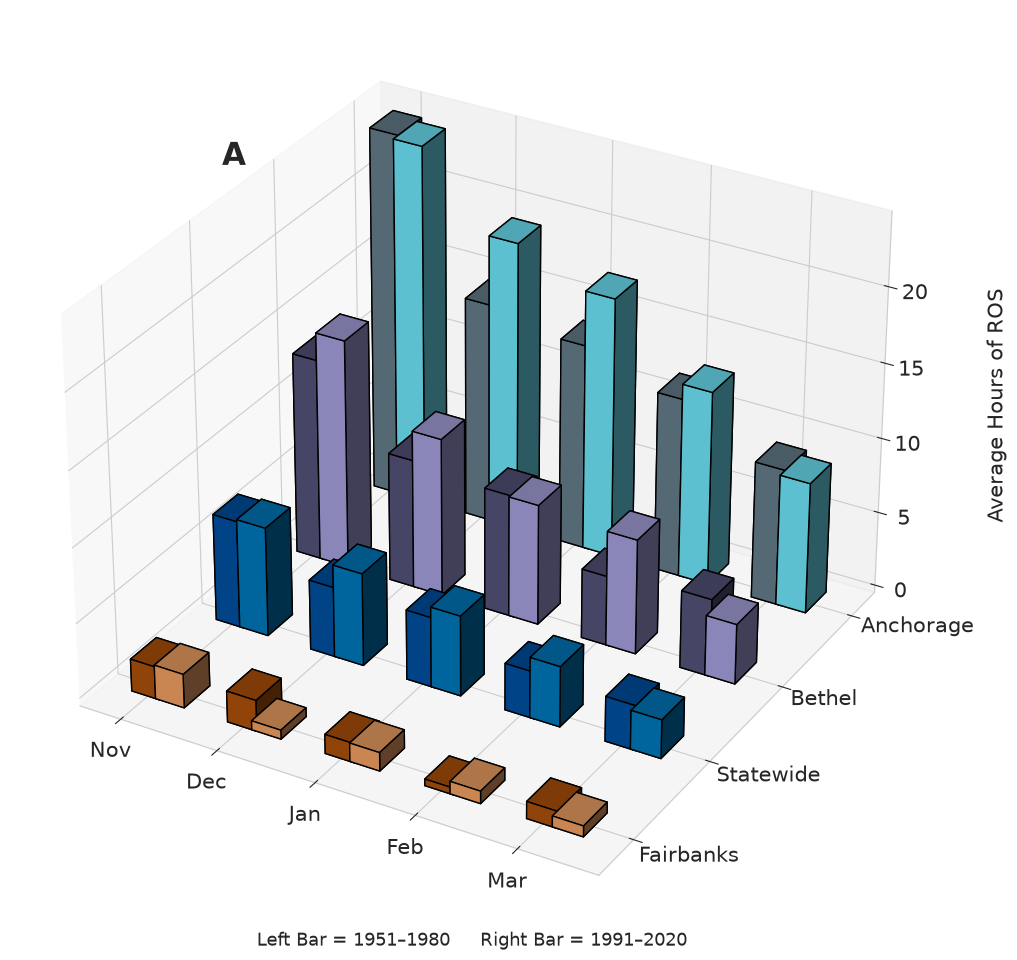

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # necessary for 3D plotting
from matplotlib.patches import Patch

borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

month_labels = ['Nov', 'Dec', 'Jan', 'Feb', 'Mar']
x = np.arange(len(month_labels))
width = 0.3
depth = 0.3 

fig = plt.figure(figsize=(25, 12)) 
ax = fig.add_subplot(111, projection='3d')
offsets = {"1951-1980": -0.1,
        "1991-2020": 0.15}

y_positions = {
    "Fairbanks": 0,
    "Anchorage": 3,
    'Statewide': 1,
    "Bethel": 2
}
# ---- Anchorage ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_tally_1950_4km, 
         color=borough_colors["Anchorageold"],  edgecolor='black', label='Anchorage 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_tally_1991_4km, 
         color=borough_colors["Anchoragenew"], edgecolor='black', label='Anchorage 1991-2020')
#---- Statewide ----

ax.bar3d(x + offsets["1951-1980"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidetally_1950_4km, 
         color=borough_colors["Statewideold"],  edgecolor='black', label='Statewide 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidetally_1991_4km, 
         color=borough_colors["Statewidenew"], edgecolor='black', label='Statewide 1991-2020')


# ---- Fairbanks ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_tally_1950_4km, 
         color=borough_colors["Fairbanksold"],  edgecolor='black', label='Fairbanks 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_tally_1991_4km, 
         color=borough_colors["Fairbanksnew"], edgecolor='black', label='Fairbanks 1991-2020')

# ---- Bethel ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_tally_1950_4km, 
         color=borough_colors["Bethelold"], edgecolor='black', label='Bethel 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_tally_1991_4km, 
         color=borough_colors["Bethelnew"], edgecolor='black', label='Bethel 1991-2020')


# Set axis labels
ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=15)

yticks = [0.2, 1.2, 2.2, 3.2]
labels = ['Fairbanks','Statewide','Bethel','Anchorage']
ax.set_yticklabels([])
ax.set_yticks(yticks)

for y, label in zip(yticks, labels):
    ax.text(x[-1]+1.2 , y-.5, 2, label, fontsize=15, ha='left', va='center')

ax.tick_params(axis='z', labelsize=15)
fig.text(0.71, 0.55, 'Average Hours of ROS', rotation=90, fontsize=15, va='center', ha='center')


fig.text(.5, .1, "Left Bar = 1951–1980     Right Bar = 1991–2020", ha='center', fontsize=13)
fig.text(0.4, 0.77, 'A', fontsize=22, fontweight='bold', va='top', ha='left')
plt.subplots_adjust(left=0.1, right=0.9)
plt.show()

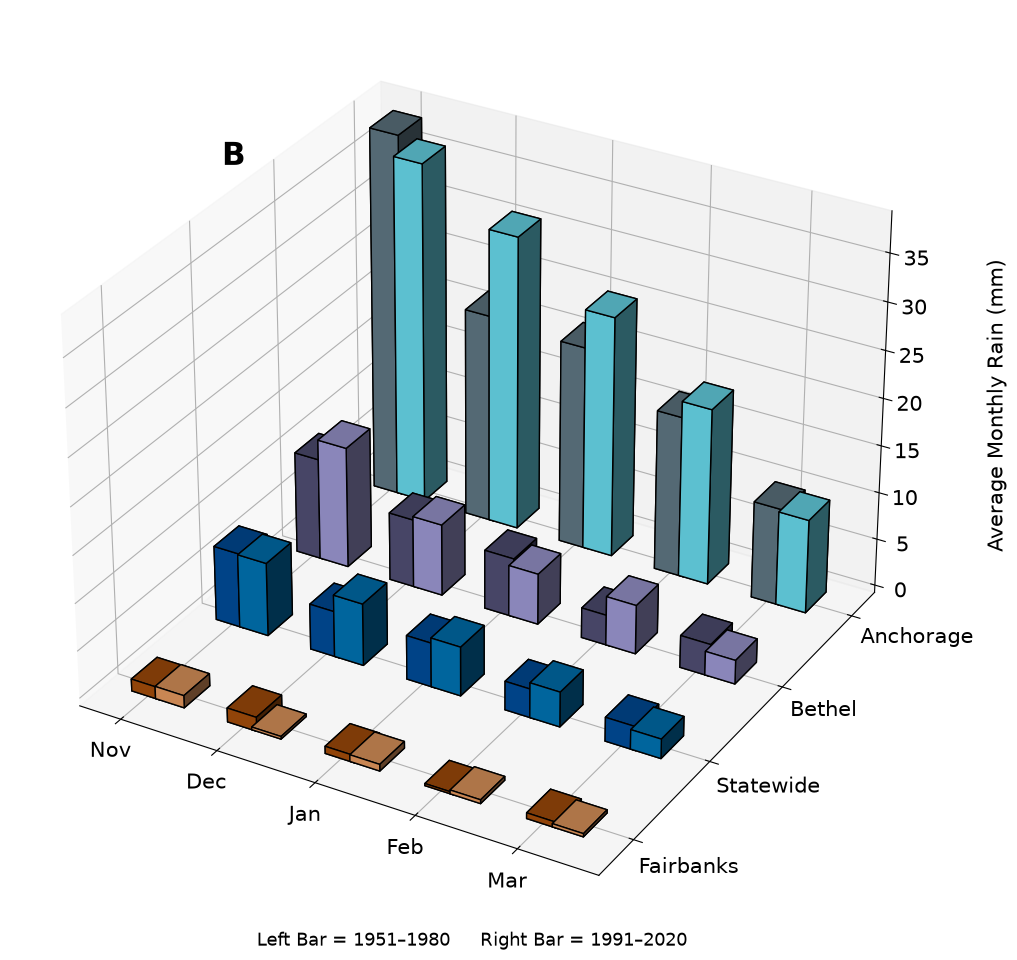

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # necessary for 3D plotting
from matplotlib.patches import Patch

borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

month_labels = ['Nov', 'Dec', 'Jan', 'Feb', 'Mar']
x = np.arange(len(month_labels))
width = 0.3
depth = 0.3 

fig = plt.figure(figsize=(25, 12)) 
ax = fig.add_subplot(111, projection='3d')
offsets = {"1951-1980": -0.1,
        "1991-2020": 0.15}

y_positions = {
    "Fairbanks": 0,
    "Anchorage": 3,
    'Statewide': 1,
    "Bethel": 2
}
# ---- Anchorage ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_sum_1950_4km, 
         color=borough_colors["Anchorageold"],  edgecolor='black', label='Anchorage 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_sum_1991_4km, 
         color=borough_colors["Anchoragenew"], edgecolor='black', label='Anchorage 1991-2020')
#---- Statewide ----

ax.bar3d(x + offsets["1951-1980"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidesum_1950_4km, 
         color=borough_colors["Statewideold"],  edgecolor='black', label='Statewide 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidesum_1991_4km, 
         color=borough_colors["Statewidenew"], edgecolor='black', label='Statewide 1991-2020')


# ---- Fairbanks ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_sum_1950_4km, 
         color=borough_colors["Fairbanksold"],  edgecolor='black', label='Fairbanks 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_sum_1991_4km, 
         color=borough_colors["Fairbanksnew"], edgecolor='black', label='Fairbanks 1991-2020')

# ---- Bethel ----
ax.bar3d(x + offsets["1951-1980"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_sum_1950_4km, 
         color=borough_colors["Bethelold"], edgecolor='black', label='Bethel 1951-1980')

ax.bar3d(x + offsets["1991-2020"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_sum_1991_4km, 
         color=borough_colors["Bethelnew"], edgecolor='black', label='Bethel 1991-2020')


# Set axis labels
ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=15)

yticks = [0.2, 1.2, 2.2, 3.2]
labels = ['Fairbanks','Statewide','Bethel','Anchorage']
ax.set_yticklabels([])
ax.set_yticks(yticks)

for y, label in zip(yticks, labels):
    ax.text(x[-1]+1.2 , y-.5, 2, label, fontsize=15, ha='left', va='center')

ax.tick_params(axis='z', labelsize=15)
fig.text(0.71, 0.55, 'Average Monthly Rain (mm)', rotation=90, fontsize=15, va='center', ha='center')

#ax.set_zlabel('Rain (mm)', fontsize=12, rotation=90)
#ax.set_title('Average Monthly Sum of ROS Rainfall \n', y=0.99,fontsize=18)

fig.text(.5, .1, "Left Bar = 1951–1980     Right Bar = 1991–2020", ha='center', fontsize=13)
fig.text(0.4, 0.77, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
plt.subplots_adjust(left=0.1, right=0.9)
plt.show()

In [19]:
'''
Mun_of_Anc_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Municipality of Anchorage']
Bethel_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Bethel Census Area']
Mat_Su_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Matanuska-Susitna Borough']
Denali_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Denali Borough']
'''

"\nMun_of_Anc_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Municipality of Anchorage']\nBethel_boundary = borough_boundaries[borough_boundaries['CommunityN'] == 'Bethel Census Area']\nMat_Su_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Matanuska-Susitna Borough']\nDenali_boundary=borough_boundaries[borough_boundaries['CommunityN'] == 'Denali Borough']\n"

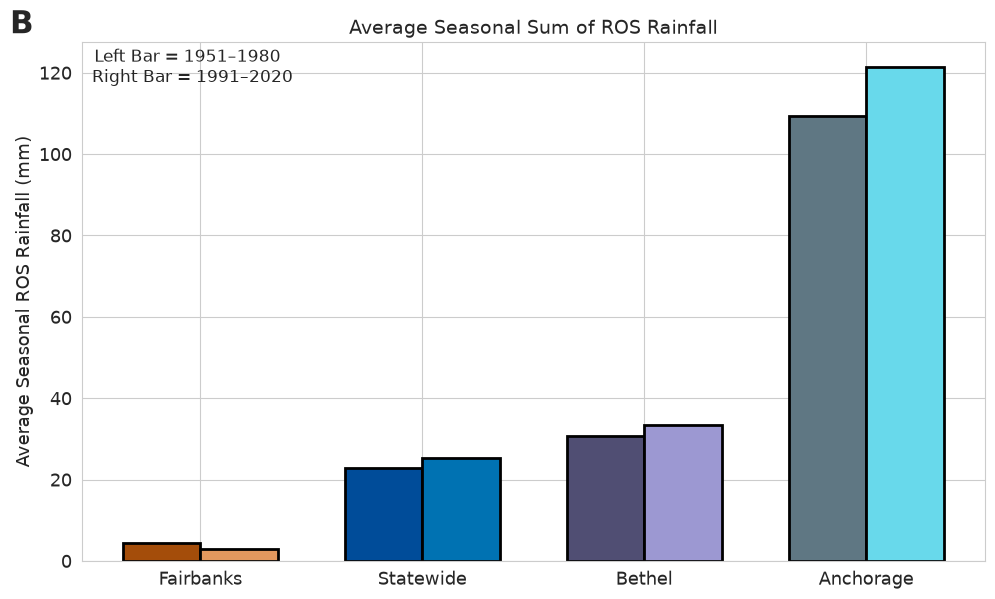

In [87]:

borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_sum_1950_4km), np.sum(statewidesum_1950_4km), np.sum(bet_sum_1950_4km), np.sum(anc_sum_1950_4km)]
new_ros = [np.sum(fai_sum_1991_4km), np.sum(statewidesum_1991_4km), np.sum(bet_sum_1991_4km),  np.sum(anc_sum_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1951-1980')
ax.bar(x + width/2, new_ros, width, color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1991-2020')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Seasonal ROS Rainfall (mm)',fontsize=13)
ax.set_title('Average Seasonal Sum of ROS Rainfall', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1951–1980 \n Right Bar = 1991–2020", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
plt.tight_layout()
plt.show()

In [88]:
diff_ros = [o - n for o, n in zip(new_ros, old_ros)]
for label, diff in zip(labels, diff_ros):
    print(f"{label}: {diff:+.3f} mm")

Fairbanks: -1.301 mm
Statewide: +2.359 mm
Bethel: +2.709 mm
Anchorage: +12.165 mm


In [89]:
monthly_ros_old=[bet_sum_1950_4km,fai_sum_1950_4km,anc_sum_1950_4km,statewidesum_1950_4km]
monthly_ros_new=[bet_sum_1991_4km,fai_sum_1991_4km,anc_sum_1991_4km,statewidesum_1991_4km]


differences = []
for old_loc, new_loc in zip(monthly_ros_old, monthly_ros_new):
    loc_diffs = []
    for old_val, new_val in zip(old_loc, new_loc):
        diff = (new_val - old_val) / old_val * 100
        loc_diffs.append(diff)
    differences.append(loc_diffs)
print(differences)

[[np.float32(19.627312), np.float32(5.1060734), np.float32(-13.850446), np.float32(62.774605), np.float32(-26.174896)], [np.float32(2.4059486), np.float32(-80.87248), np.float32(-7.159322), np.float32(79.85999), np.float32(-44.015373)], [np.float32(-6.0137563), np.float32(41.254436), np.float32(18.61471), np.float32(9.985826), np.float32(-3.1841471)], [np.float32(-1.5273523), np.float32(36.44361), np.float32(11.593733), np.float32(21.643055), np.float32(-18.525229)]]


In [90]:
old_ros = [np.sum(fai_sum_1950_4km), np.sum(statewidesum_1950_4km), np.sum(bet_sum_1950_4km), np.sum(anc_sum_1950_4km)]
new_ros = [np.sum(fai_sum_1991_4km), np.sum(statewidesum_1991_4km), np.sum(bet_sum_1991_4km),  np.sum(anc_sum_1991_4km)]

for var in old_ros:
    diff= (new_ros[old_ros.index(var)]-old_ros[old_ros.index(var)] )/old_ros[old_ros.index(var)]*100
    print(diff)

-30.143076
10.32047
8.808305
11.130746


Standard error 
-

In [104]:
#era5_4km_1991_2020['rain_ros_sum']
annual_boot_1991=era5_4km_1991_2020['rain_ros_sum'].sum(axis=1)
#era5_4km_1950_1979['rain_ros_sum']
annual_boot_1950=era5_4km_1950_1979['rain_ros_sum'].sum(axis=1)

In [105]:
# Apply mask and spatial mean to get one value per season per region
def get_regional_seasonal(annual_data, shapefile=None):
    annual_data = annual_data.compute()  # load from dask
    if shapefile is not None:
        masked = borough_land_mask(shapefile, annual_data, annual_data.XLAT, annual_data.XLONG)
    else:
        masked = annual_data
    return masked.mean(dim=['south_north', 'west_east']).values

fai_seasonal_1950   = get_regional_seasonal(annual_boot_1950, FNSB_boundary)
anc_seasonal_1950   = get_regional_seasonal(annual_boot_1950, Mun_of_Anc_boundary)
bet_seasonal_1950   = get_regional_seasonal(annual_boot_1950, Bethel_boundary)
state_seasonal_1950 = get_regional_seasonal(annual_boot_1950)

fai_seasonal_1991   = get_regional_seasonal(annual_boot_1991, FNSB_boundary)
anc_seasonal_1991   = get_regional_seasonal(annual_boot_1991, Mun_of_Anc_boundary)
bet_seasonal_1991   = get_regional_seasonal(annual_boot_1991, Bethel_boundary)
state_seasonal_1991 = get_regional_seasonal(annual_boot_1991)

In [103]:
tally_annual_boot_1991=era5_4km_1991_2020['ros_tally'].sum(axis=1)
#era5_4km_1950_1979['rain_ros_sum']
tally_annual_boot_1950=era5_4km_1950_1979['ros_tally'].sum(axis=1)

tally_fai_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, FNSB_boundary)
tally_anc_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Mun_of_Anc_boundary)
tally_bet_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Bethel_boundary)
tally_state_seasonal_1950 = get_regional_seasonal(tally_annual_boot_1950)

tally_fai_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, FNSB_boundary)
tally_anc_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Mun_of_Anc_boundary)
tally_bet_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Bethel_boundary)
tally_state_seasonal_1991 = get_regional_seasonal(tally_annual_boot_1991)

In [106]:
def standard_error(x):
    x = np.asarray(x)
    return np.std(x, ddof=1) / np.sqrt(len(x))

In [107]:
se_fai_seasonal_1950=standard_error(fai_seasonal_1950)
se_anc_seasonal_1950=standard_error(anc_seasonal_1950)
se_bet_seasonal_1950=standard_error(bet_seasonal_1950)
se_state_seasonal_1950=standard_error(state_seasonal_1950)

se_fai_seasonal_1991=standard_error(fai_seasonal_1991)
se_anc_seasonal_1991=standard_error(anc_seasonal_1991)
se_bet_seasonal_1991=standard_error(bet_seasonal_1991)
se_state_seasonal_1991=standard_error(state_seasonal_1991)

se_tally_fai_seasonal_1950=standard_error(tally_fai_seasonal_1950)
se_tally_anc_seasonal_1950=standard_error(tally_anc_seasonal_1950)
se_tally_bet_seasonal_1950=standard_error(tally_bet_seasonal_1950)
se_tally_state_seasonal_1950=standard_error(tally_state_seasonal_1950)

se_tally_fai_seasonal_1991=standard_error(tally_fai_seasonal_1991)
se_tally_anc_seasonal_1991=standard_error(tally_anc_seasonal_1991)
se_tally_bet_seasonal_1991=standard_error(tally_bet_seasonal_1991)
se_tally_state_seasonal_1991=standard_error(tally_state_seasonal_1991)

In [ ]:
tally_annual_boot_1991=era5_4km_1991_2020['ros_tally'].sum(axis=1)
#era5_4km_1950_1979['rain_ros_sum']
tally_annual_boot_1950=era5_4km_1950_1979['ros_tally'].sum(axis=1)

tally_fai_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, FNSB_boundary)
tally_anc_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Mun_of_Anc_boundary)
tally_bet_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Bethel_boundary)
tally_state_seasonal_1950 = get_regional_seasonal(tally_annual_boot_1950)

tally_fai_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, FNSB_boundary)
tally_anc_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Mun_of_Anc_boundary)
tally_bet_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Bethel_boundary)
tally_state_seasonal_1991 = get_regional_seasonal(tally_annual_boot_1991)


std_tally_fai_seasonal_1950=np.std(tally_fai_seasonal_1950)
std_tally_anc_seasonal_1950=np.std(tally_anc_seasonal_1950)
std_tally_bet_seasonal_1950=np.std(tally_bet_seasonal_1950)
std_tally_state_seasonal_1950=np.std(tally_state_seasonal_1950)

std_tally_fai_seasonal_1991=np.std(tally_fai_seasonal_1991)
std_tally_anc_seasonal_1991=np.std(tally_anc_seasonal_1991)
std_tally_bet_seasonal_1991=np.std(tally_bet_seasonal_1991)
std_tally_state_seasonal_1991=np.std(tally_state_seasonal_1991)

tally_fai_1950_val = np.mean(tally_fai_seasonal_1950)
tally_anc_1950_val = np.mean(tally_anc_seasonal_1950)
tally_bet_1950_val = np.mean(tally_bet_seasonal_1950)
tally_state_1950_val = np.mean(tally_state_seasonal_1950)

tally_fai_1991_val = np.mean(tally_fai_seasonal_1991)
tally_anc_1991_val = np.mean(tally_anc_seasonal_1991)
tally_bet_1991_val = np.mean(tally_bet_seasonal_1991)
tally_state_1991_val = np.mean(tally_state_seasonal_1991)



std_fai_seasonal_1950=np.std(fai_seasonal_1950)
std_anc_seasonal_1950=np.std(anc_seasonal_1950)
std_bet_seasonal_1950=np.std(bet_seasonal_1950)
std_state_seasonal_1950=np.std(state_seasonal_1950)

std_fai_seasonal_1991=np.std(fai_seasonal_1991)
std_anc_seasonal_1991=np.std(anc_seasonal_1991)
std_bet_seasonal_1991=np.std(bet_seasonal_1991)
std_state_seasonal_1991=np.std(state_seasonal_1991)

fai_1950_val = np.mean(fai_seasonal_1950)
anc_1950_val = np.mean(anc_seasonal_1950)
bet_1950_val = np.mean(bet_seasonal_1950)
state_1950_val = np.mean(state_seasonal_1950)

fai_1991_val = np.mean(fai_seasonal_1991)
anc_1991_val = np.mean(anc_seasonal_1991)
bet_1991_val = np.mean(bet_seasonal_1991)
state_1991_val = np.mean(state_seasonal_1991)


print(std_fai_seasonal_1950,std_anc_seasonal_1950,std_bet_seasonal_1950,std_state_seasonal_1950)
print(std_fai_seasonal_1991,std_anc_seasonal_1991,std_bet_seasonal_1991,std_state_seasonal_1991)
 
 
print(f"1950–1979 Fairbanks: {fai_1950_val:.2f} mm ± {se_fai_seasonal_1950:.2f} mm")
print(f"1950–1979 Anchorage: {anc_1950_val:.2f} mm ± {se_anc_seasonal_1950:.2f} mm")
print(f"1950–1979 Bethel: {bet_1950_val:.2f} mm ± {se_bet_seasonal_1950:.2f} mm")
print(f"1950–1979 Statewide: {state_1950_val:.2f} mm ± {se_state_seasonal_1950:.2f} mm")

print(f"1991–2020 Fairbanks: {fai_1991_val:.2f} mm ± {se_fai_seasonal_1991:.2f} mm")
print(f"1991–2020 Anchorage: {anc_1991_val:.2f} mm ± {se_anc_seasonal_1991:.2f} mm")
print(f"1991–2020 Bethel: {bet_1991_val:.2f} mm ± {se_bet_seasonal_1991:.2f} mm")
print(f"1991–2020 Statewide: {state_1991_val:.2f} mm ± {se_state_seasonal_1991:.2f} mm")

5.6331825 68.339134 15.28166 5.953557
3.6606886 49.09786 15.658468 5.2600284
1950–1979 Fairbanks: 4.32 mm ± 1.05 mm
1950–1979 Anchorage: 100.78 mm ± 12.69 mm
1950–1979 Bethel: 29.04 mm ± 2.84 mm
1950–1979 Statewide: 13.24 mm ± 1.11 mm
1991–2020 Fairbanks: 3.01 mm ± 0.68 mm
1991–2020 Anchorage: 111.99 mm ± 9.12 mm
1991–2020 Bethel: 31.60 mm ± 2.91 mm
1991–2020 Statewide: 14.61 mm ± 0.98 mm


In [109]:
se_old = [
    se_fai_seasonal_1950,
    se_state_seasonal_1950,
    se_bet_seasonal_1950,
    se_anc_seasonal_1950
]

se_new = [
    se_fai_seasonal_1991,
    se_state_seasonal_1991,
    se_bet_seasonal_1991,
    se_anc_seasonal_1991
]

se_old_tally = [
    se_tally_fai_seasonal_1950,
    se_tally_state_seasonal_1950,
    se_tally_bet_seasonal_1950,
    se_tally_anc_seasonal_1950
]

se_new_tally= [
    se_tally_fai_seasonal_1991,
    se_tally_state_seasonal_1991,
    se_tally_bet_seasonal_1991,
    se_tally_anc_seasonal_1991
]

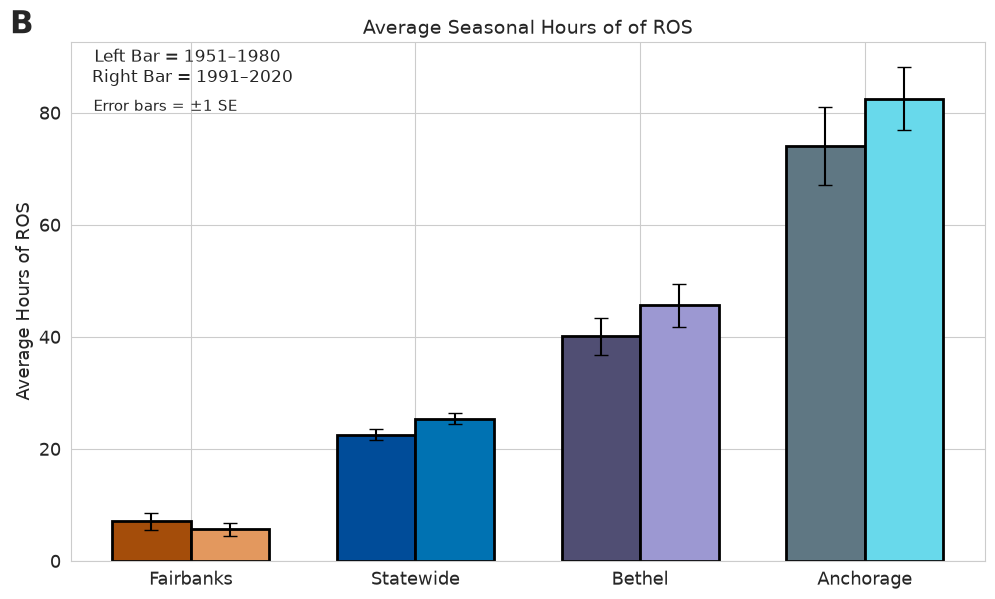

In [110]:
borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_tally_1950_4km), np.sum(statewidetally_1950_4km), np.sum(bet_tally_1950_4km), np.sum(anc_tally_1950_4km)]
new_ros = [np.sum(fai_tally_1991_4km), np.sum(statewidetally_1991_4km), np.sum(bet_tally_1991_4km),  np.sum(anc_tally_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width,yerr=se_old_tally,    capsize=5, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1951-1980')
ax.bar(x + width/2, new_ros, width, yerr=se_new_tally,     capsize=5,color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1991-2020')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Hours of ROS',fontsize=13)
ax.set_title('Average Seasonal Hours of of ROS', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1951–1980 \n Right Bar = 1991–2020", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.89,"Error bars = ±1 SE",transform=ax.transAxes,va='top',fontsize=11)
plt.tight_layout()
plt.show()

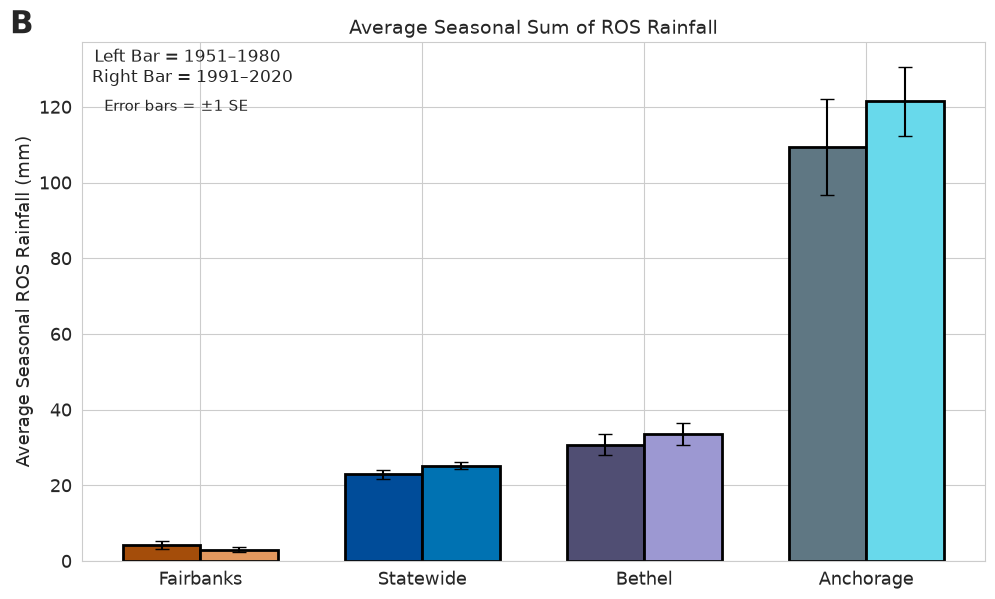

In [100]:
borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_sum_1950_4km), np.sum(statewidesum_1950_4km), np.sum(bet_sum_1950_4km), np.sum(anc_sum_1950_4km)]
new_ros = [np.sum(fai_sum_1991_4km), np.sum(statewidesum_1991_4km), np.sum(bet_sum_1991_4km),  np.sum(anc_sum_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width,yerr=se_old,    capsize=5, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1951-1980')
ax.bar(x + width/2, new_ros, width, yerr=se_new,     capsize=5,color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1991-2020')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Seasonal ROS Rainfall (mm)',fontsize=13)
ax.set_title('Average Seasonal Sum of ROS Rainfall', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1951–1980 \n Right Bar = 1991–2020", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.89,"Error bars = ±1 SE",transform=ax.transAxes,va='top',fontsize=11)
plt.tight_layout()
plt.show()

Showing variation in cliamte normals?
-

In [118]:
'''1991-2020
1981-2010
1971-2000
1961-1990
1951-1980'''

era5_4km_1950_1979 = era5_4km.sel(season=slice('1965-1966', '1995-1996'))
era5_4km_1991_2020 = era5_4km.sel(season=slice('1995-1996', '2025-2026'))

# 1950-1979
era5_4km_nov_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_1950_1979 = era5_4km_1950_1979['rain_ros_sum'].sel(month=3).mean(dim='season')


# 1991-2020
era5_4km_nov_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=11).mean(dim='season')
era5_4km_dec_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=12).mean(dim='season')
era5_4km_jan_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=1).mean(dim='season')
era5_4km_feb_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=2).mean(dim='season')
era5_4km_mar_ros_1991_2020 = era5_4km_1991_2020['rain_ros_sum'].sel(month=3).mean(dim='season')


era5_4km_1950_1979_monthly_rain_ros_sum = {
    'nov': era5_4km_1950_1979['rain_ros_sum'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1950_1979['rain_ros_sum'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1950_1979['rain_ros_sum'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1950_1979['rain_ros_sum'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1950_1979['rain_ros_sum'].sel(month=3).mean(dim='season')}

era5_4km_1991_2020_monthly_rain_ros_sum={
    'nov': era5_4km_1991_2020['rain_ros_sum'].sel(month=11).mean(dim='season'),
    'dec': era5_4km_1991_2020['rain_ros_sum'].sel(month=12).mean(dim='season'),
    'jan': era5_4km_1991_2020['rain_ros_sum'].sel(month=1).mean(dim='season'),
    'feb': era5_4km_1991_2020['rain_ros_sum'].sel(month=2).mean(dim='season'),
    'mar': era5_4km_1991_2020['rain_ros_sum'].sel(month=3).mean(dim='season') }


anc_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, Mun_of_Anc_boundary)
anc_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, Mun_of_Anc_boundary)
anc_sum_1950_4km = monthly_avg(anc_era5_4km_1950_1979)
anc_sum_1991_4km = monthly_avg(anc_era5_4km_1991_2020)

bet_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, Bethel_boundary)
bet_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, Bethel_boundary)
bet_sum_1950_4km = monthly_avg(bet_era5_4km_1950_1979)
bet_sum_1991_4km = monthly_avg(bet_era5_4km_1991_2020)

fai_era5_4km_1950_1979 = apply_borough_mask(era5_4km_1950_1979_monthly_rain_ros_sum, FNSB_boundary)
fai_era5_4km_1991_2020 = apply_borough_mask(era5_4km_1991_2020_monthly_rain_ros_sum, FNSB_boundary)
fai_sum_1950_4km = monthly_avg(fai_era5_4km_1950_1979)
fai_sum_1991_4km = monthly_avg(fai_era5_4km_1991_2020)  

statewidesum_1950_4km = monthly_avg(era5_4km_1950_1979_monthly_rain_ros_sum)
statewidesum_1991_4km = monthly_avg(era5_4km_1991_2020_monthly_rain_ros_sum)

In [119]:
tally_annual_boot_1991=era5_4km_1991_2020['ros_tally'].sum(axis=1)
#era5_4km_1950_1979['rain_ros_sum']
tally_annual_boot_1950=era5_4km_1950_1979['ros_tally'].sum(axis=1)

tally_fai_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, FNSB_boundary)
tally_anc_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Mun_of_Anc_boundary)
tally_bet_seasonal_1950   = get_regional_seasonal(tally_annual_boot_1950, Bethel_boundary)
tally_state_seasonal_1950 = get_regional_seasonal(tally_annual_boot_1950)

tally_fai_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, FNSB_boundary)
tally_anc_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Mun_of_Anc_boundary)
tally_bet_seasonal_1991   = get_regional_seasonal(tally_annual_boot_1991, Bethel_boundary)
tally_state_seasonal_1991 = get_regional_seasonal(tally_annual_boot_1991)

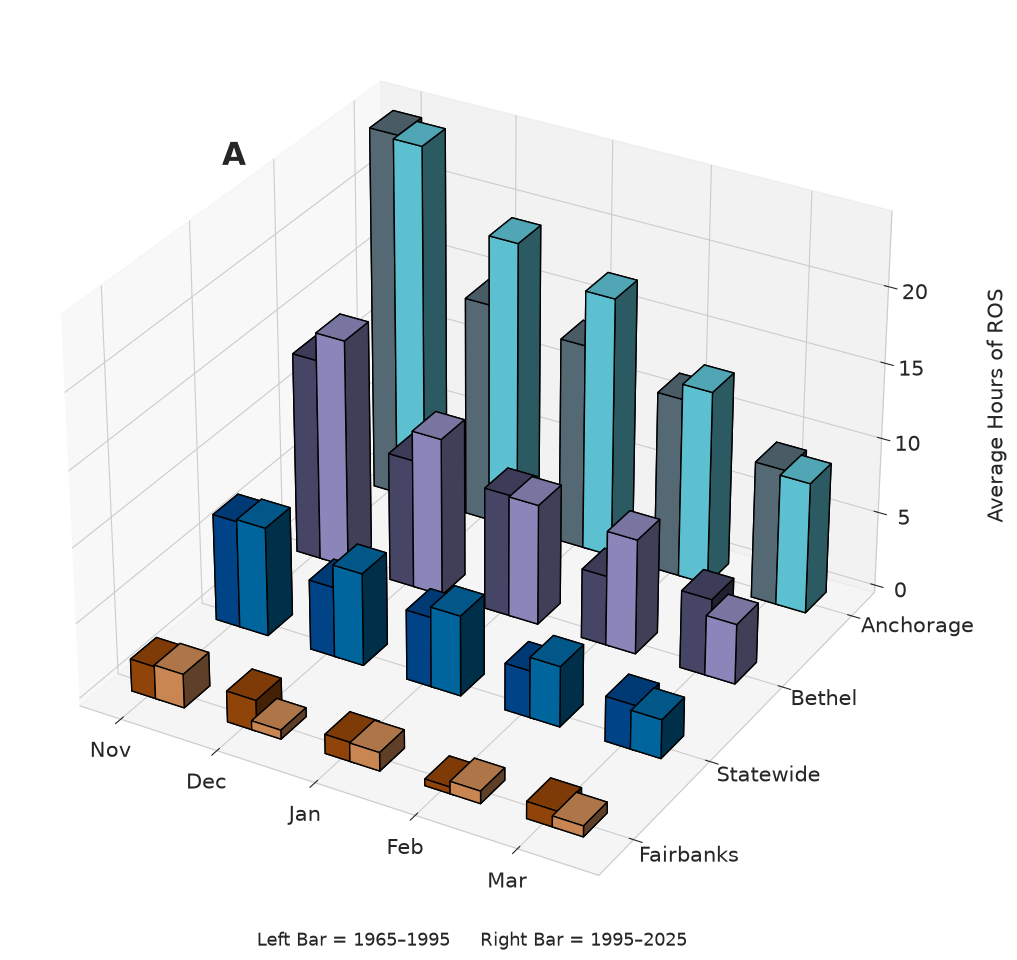

In [120]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # necessary for 3D plotting
from matplotlib.patches import Patch

borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

month_labels = ['Nov', 'Dec', 'Jan', 'Feb', 'Mar']
x = np.arange(len(month_labels))
width = 0.3
depth = 0.3 

fig = plt.figure(figsize=(25, 12)) 
ax = fig.add_subplot(111, projection='3d')
offsets = {"1965-1995": -0.1,
        "1995-2025": 0.15}

y_positions = {
    "Fairbanks": 0,
    "Anchorage": 3,
    'Statewide': 1,
    "Bethel": 2
}
# ---- Anchorage ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_tally_1950_4km, 
         color=borough_colors["Anchorageold"],  edgecolor='black', label='Anchorage 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_tally_1991_4km, 
         color=borough_colors["Anchoragenew"], edgecolor='black', label='Anchorage 1995-2025')
#---- Statewide ----

ax.bar3d(x + offsets["1965-1995"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidetally_1950_4km, 
         color=borough_colors["Statewideold"],  edgecolor='black', label='Statewide 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidetally_1991_4km, 
         color=borough_colors["Statewidenew"], edgecolor='black', label='Statewide 1995-2025')


# ---- Fairbanks ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_tally_1950_4km, 
         color=borough_colors["Fairbanksold"],  edgecolor='black', label='Fairbanks 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_tally_1991_4km, 
         color=borough_colors["Fairbanksnew"], edgecolor='black', label='Fairbanks 1995-2025')

# ---- Bethel ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_tally_1950_4km, 
         color=borough_colors["Bethelold"], edgecolor='black', label='Bethel 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_tally_1991_4km, 
         color=borough_colors["Bethelnew"], edgecolor='black', label='Bethel 1995-2025')


# Set axis labels
ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=15)

yticks = [0.2, 1.2, 2.2, 3.2]
labels = ['Fairbanks','Statewide','Bethel','Anchorage']
ax.set_yticklabels([])
ax.set_yticks(yticks)

for y, label in zip(yticks, labels):
    ax.text(x[-1]+1.2 , y-.5, 2, label, fontsize=15, ha='left', va='center')

ax.tick_params(axis='z', labelsize=15)
fig.text(0.71, 0.55, 'Average Hours of ROS', rotation=90, fontsize=15, va='center', ha='center')


fig.text(.5, .1, "Left Bar = 1965–1995     Right Bar = 1995–2025", ha='center', fontsize=13)
fig.text(0.4, 0.77, 'A', fontsize=22, fontweight='bold', va='top', ha='left')
plt.subplots_adjust(left=0.1, right=0.9)
plt.show()

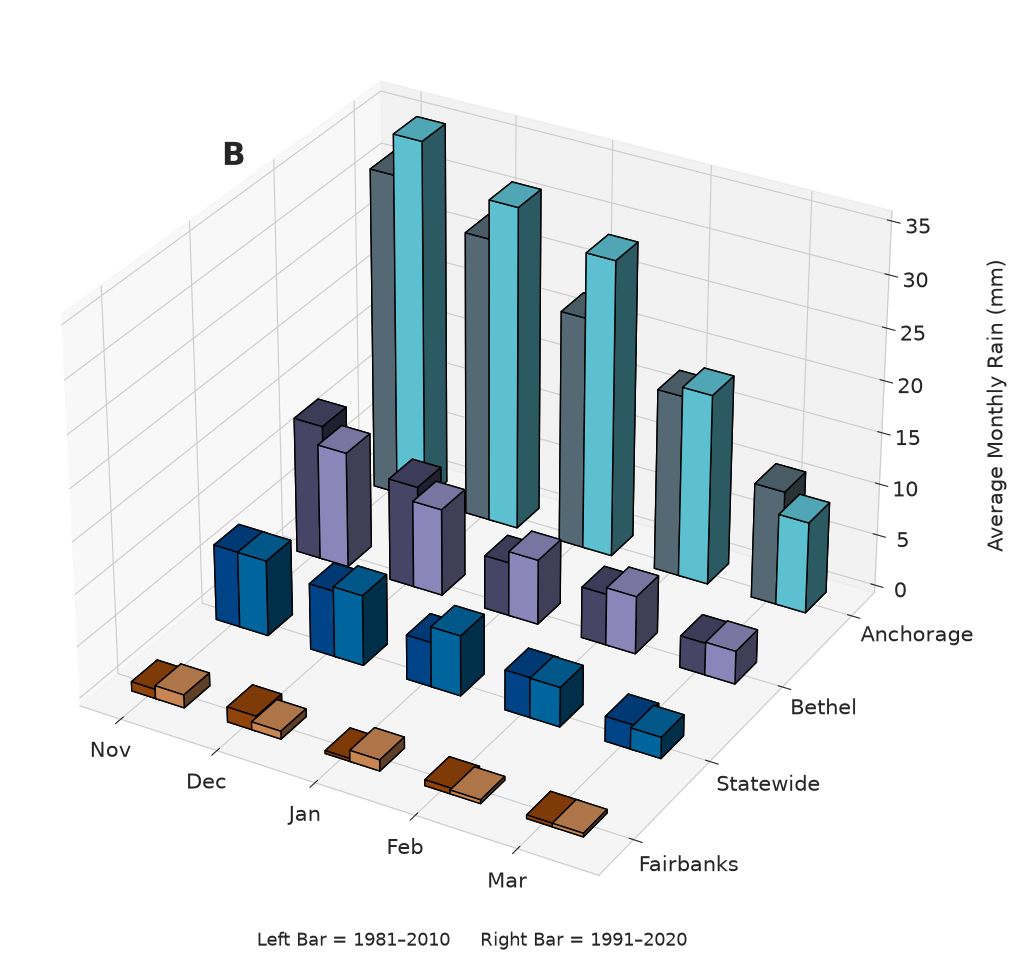

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # necessary for 3D plotting
from matplotlib.patches import Patch

borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

month_labels = ['Nov', 'Dec', 'Jan', 'Feb', 'Mar']
x = np.arange(len(month_labels))
width = 0.3
depth = 0.3 

fig = plt.figure(figsize=(25, 12)) 
ax = fig.add_subplot(111, projection='3d')
offsets = {"1965-1995": -0.1,
        "1995-2025": 0.15}

y_positions = {
    "Fairbanks": 0,
    "Anchorage": 3,
    'Statewide': 1,
    "Bethel": 2
}
# ---- Anchorage ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_sum_1950_4km, 
         color=borough_colors["Anchorageold"],  edgecolor='black', label='Anchorage 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Anchorage"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, anc_sum_1991_4km, 
         color=borough_colors["Anchoragenew"], edgecolor='black', label='Anchorage 1995-2025')
#---- Statewide ----

ax.bar3d(x + offsets["1965-1995"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidesum_1950_4km, 
         color=borough_colors["Statewideold"],  edgecolor='black', label='Statewide 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Statewide"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, statewidesum_1991_4km, 
         color=borough_colors["Statewidenew"], edgecolor='black', label='Statewide 1995-2025')


# ---- Fairbanks ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_sum_1950_4km, 
         color=borough_colors["Fairbanksold"],  edgecolor='black', label='Fairbanks 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Fairbanks"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, fai_sum_1991_4km, 
         color=borough_colors["Fairbanksnew"], edgecolor='black', label='Fairbanks 1995-2025')

# ---- Bethel ----
ax.bar3d(x + offsets["1965-1995"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_sum_1950_4km, 
         color=borough_colors["Bethelold"], edgecolor='black', label='Bethel 1965-1995')

ax.bar3d(x + offsets["1995-2025"], y_positions["Bethel"]*np.ones_like(x), np.zeros_like(x), 
         width, depth, bet_sum_1991_4km, 
         color=borough_colors["Bethelnew"], edgecolor='black', label='Bethel 1995-2025')


# Set axis labels
ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=15)

yticks = [0.2, 1.2, 2.2, 3.2]
labels = ['Fairbanks','Statewide','Bethel','Anchorage']
ax.set_yticklabels([])
ax.set_yticks(yticks)

for y, label in zip(yticks, labels):
    ax.text(x[-1]+1.2 , y-.5, 2, label, fontsize=15, ha='left', va='center')

ax.tick_params(axis='z', labelsize=15)
fig.text(0.71, 0.55, 'Average Monthly Rain (mm)', rotation=90, fontsize=15, va='center', ha='center')

#ax.set_zlabel('Rain (mm)', fontsize=12, rotation=90)
#ax.set_title('Average Monthly Sum of ROS Rainfall \n', y=0.99,fontsize=18)

fig.text(.5, .1, "Left Bar = 1981–2010     Right Bar = 1991–2020", ha='center', fontsize=13)
fig.text(0.4, 0.77, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
plt.subplots_adjust(left=0.1, right=0.9)
plt.show()

Seasonal
-

In [122]:
se_fai_seasonal_1950=standard_error(fai_seasonal_1950)
se_anc_seasonal_1950=standard_error(anc_seasonal_1950)
se_bet_seasonal_1950=standard_error(bet_seasonal_1950)
se_state_seasonal_1950=standard_error(state_seasonal_1950)

se_fai_seasonal_1991=standard_error(fai_seasonal_1991)
se_anc_seasonal_1991=standard_error(anc_seasonal_1991)
se_bet_seasonal_1991=standard_error(bet_seasonal_1991)
se_state_seasonal_1991=standard_error(state_seasonal_1991)


std_fai_seasonal_1950=np.std(fai_seasonal_1950)
std_anc_seasonal_1950=np.std(anc_seasonal_1950)
std_bet_seasonal_1950=np.std(bet_seasonal_1950)
std_state_seasonal_1950=np.std(state_seasonal_1950)

std_fai_seasonal_1991=np.std(fai_seasonal_1991)
std_anc_seasonal_1991=np.std(anc_seasonal_1991)
std_bet_seasonal_1991=np.std(bet_seasonal_1991)
std_state_seasonal_1991=np.std(state_seasonal_1991)

fai_1950_val = np.mean(fai_seasonal_1950)
anc_1950_val = np.mean(anc_seasonal_1950)
bet_1950_val = np.mean(bet_seasonal_1950)
state_1950_val = np.mean(state_seasonal_1950)

fai_1991_val = np.mean(fai_seasonal_1991)
anc_1991_val = np.mean(anc_seasonal_1991)
bet_1991_val = np.mean(bet_seasonal_1991)
state_1991_val = np.mean(state_seasonal_1991)


print(std_fai_seasonal_1950,std_anc_seasonal_1950,std_bet_seasonal_1950,std_state_seasonal_1950)
print(std_fai_seasonal_1991,std_anc_seasonal_1991,std_bet_seasonal_1991,std_state_seasonal_1991)
 
 
print(f"1950–1979 Fairbanks: {fai_1950_val:.2f} mm ± {se_fai_seasonal_1950:.2f} mm")
print(f"1950–1979 Anchorage: {anc_1950_val:.2f} mm ± {se_anc_seasonal_1950:.2f} mm")
print(f"1950–1979 Bethel: {bet_1950_val:.2f} mm ± {se_bet_seasonal_1950:.2f} mm")
print(f"1950–1979 Statewide: {state_1950_val:.2f} mm ± {se_state_seasonal_1950:.2f} mm")

print(f"1991–2020 Fairbanks: {fai_1991_val:.2f} mm ± {se_fai_seasonal_1991:.2f} mm")
print(f"1991–2020 Anchorage: {anc_1991_val:.2f} mm ± {se_anc_seasonal_1991:.2f} mm")
print(f"1991–2020 Bethel: {bet_1991_val:.2f} mm ± {se_bet_seasonal_1991:.2f} mm")
print(f"1991–2020 Statewide: {state_1991_val:.2f} mm ± {se_state_seasonal_1991:.2f} mm")

5.6331825 68.339134 15.28166 5.953557
3.6606886 49.09786 15.658468 5.2600284
1950–1979 Fairbanks: 4.32 mm ± 1.05 mm
1950–1979 Anchorage: 100.78 mm ± 12.69 mm
1950–1979 Bethel: 29.04 mm ± 2.84 mm
1950–1979 Statewide: 13.24 mm ± 1.11 mm
1991–2020 Fairbanks: 3.01 mm ± 0.68 mm
1991–2020 Anchorage: 111.99 mm ± 9.12 mm
1991–2020 Bethel: 31.60 mm ± 2.91 mm
1991–2020 Statewide: 14.61 mm ± 0.98 mm


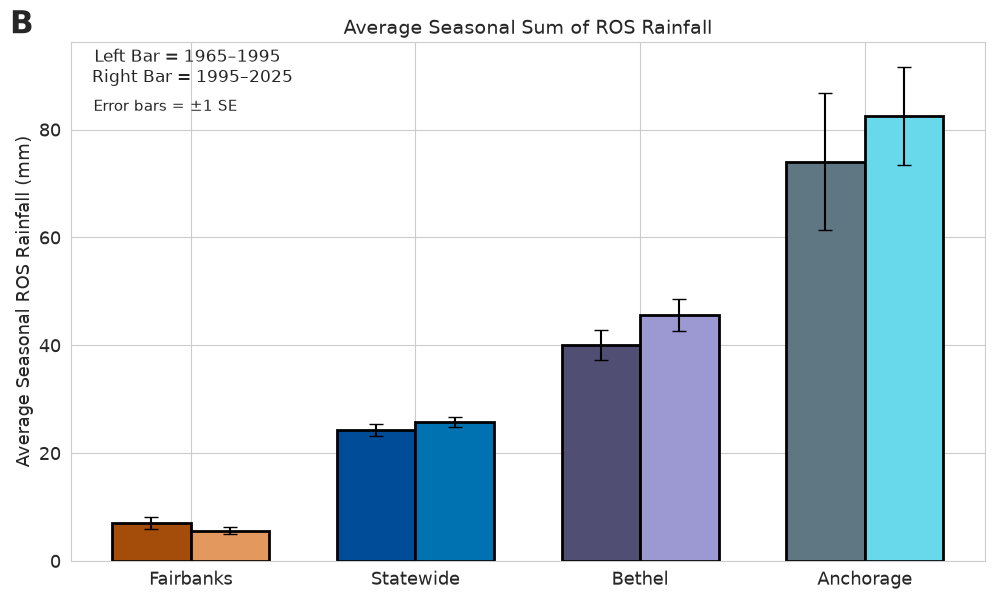

In [ ]:
borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_tally_1950_4km), np.sum(statewidesum_1950_4km), np.sum(bet_tally_1950_4km), np.sum(anc_tally_1950_4km)]
new_ros = [np.sum(fai_tally_1991_4km), np.sum(statewidesum_1991_4km), np.sum(bet_tally_1991_4km),  np.sum(anc_tally_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width,yerr=se_old,    capsize=5, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1965-1995')
ax.bar(x + width/2, new_ros, width, yerr=se_new,     capsize=5,color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1995-2025')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Seasonal ROS Rainfall (mm)',fontsize=13)
ax.set_title('Average Seasonal Sum of ROS Rainfall', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1965–1995 \n Right Bar = 1995–2025", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.89,"Error bars = ±1 SE",transform=ax.transAxes,va='top',fontsize=11)
plt.tight_layout()
plt.show()

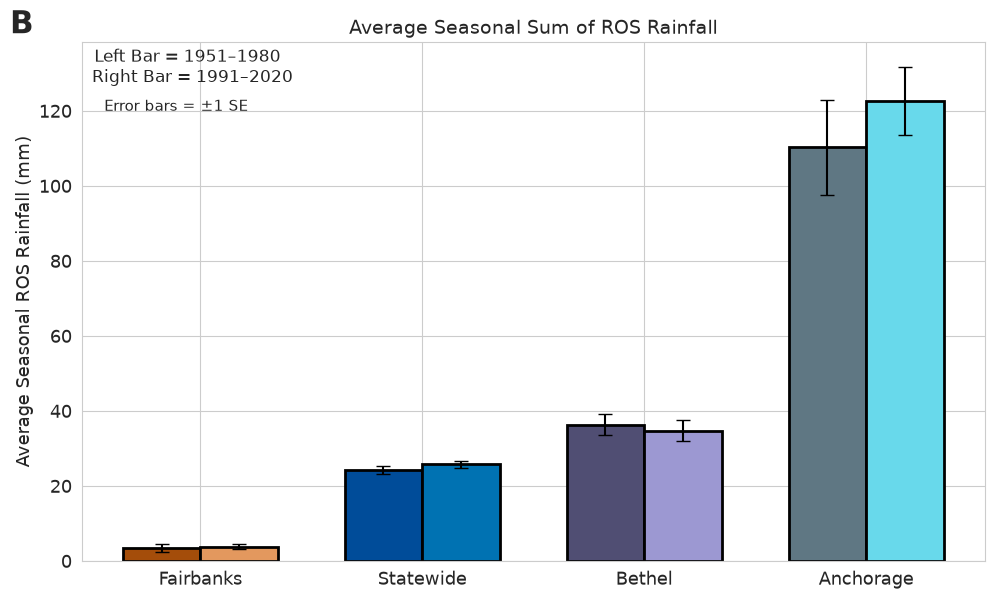

In [124]:
borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_sum_1950_4km), np.sum(statewidesum_1950_4km), np.sum(bet_sum_1950_4km), np.sum(anc_sum_1950_4km)]
new_ros = [np.sum(fai_sum_1991_4km), np.sum(statewidesum_1991_4km), np.sum(bet_sum_1991_4km),  np.sum(anc_sum_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width,yerr=se_old,    capsize=5, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1951-1980')
ax.bar(x + width/2, new_ros, width, yerr=se_new,     capsize=5,color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1991-2020')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Seasonal ROS Rainfall (mm)',fontsize=13)
ax.set_title('Average Seasonal Sum of ROS Rainfall', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1951–1980 \n Right Bar = 1991–2020", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.89,"Error bars = ±1 SE",transform=ax.transAxes,va='top',fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
borough_colors = {
    'Anchorageold': "#5f7783",   # light blue
    "Anchoragenew": "#68d9eb",   # teal green
    "Fairbanksnew": "#e3985e",   # orange
    "Fairbanksold": "#A44D0A",   # orange
    "Bethelnew": "#9c98d2",      # purple
    "Bethelold": "#504e73",      # purple
    "Statewidenew": "#0072B2" ,   # blue
    "Statewideold": "#004c99"     # dark blue
}

labels = ['Fairbanks','Statewide','Bethel','Anchorage']
x = np.arange(len(labels))
width = 0.35  # width of each bar

# Values per period
old_ros = [np.sum(fai_tally_1950_4km), np.sum(statewidetally_1950_4km), np.sum(bet_tally_1950_4km), np.sum(anc_tally_1950_4km)]
new_ros = [np.sum(fai_tally_1991_4km), np.sum(statewidetally_1991_4km), np.sum(bet_tally_1991_4km),  np.sum(anc_tally_1991_4km)]



fig, ax = plt.subplots(figsize=(10,6))

# Plot bars
ax.bar(x - width/2, old_ros, width,yerr=se_old_tally,    capsize=5, color=[borough_colors['Fairbanksold'], borough_colors['Statewideold'], borough_colors['Bethelold'], borough_colors['Anchorageold']], edgecolor='black',  linewidth=2, label='1951-1980')
ax.bar(x + width/2, new_ros, width, yerr=se_new_tally,     capsize=5,color=[borough_colors['Fairbanksnew'], borough_colors['Statewidenew'], borough_colors['Bethelnew'], borough_colors['Anchoragenew']], edgecolor='black',   linewidth=2,label='1991-2020')

# Labels
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=13)
ax.set_ylabel('Average Hours of ROS',fontsize=13)
ax.set_title('Average Seasonal Hours of of ROS', fontsize=14)
ax.tick_params(axis='y', labelsize=13)
fig.text(0.19, 0.87, "Left Bar = 1951–1980 \n Right Bar = 1991–2020", ha='center', fontsize=12)
fig.text(0.01, 0.99, 'B', fontsize=22, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.89,"Error bars = ±1 SE",transform=ax.transAxes,va='top',fontsize=11)
plt.tight_layout()
plt.show()